# Topic Modeling
### Bert Sentence Embedding, LDA, and K-means Clustering

#### Concatenate the sentence embeddings with LDA, use an autoencoder to get the latent representation and perform K-means to perform clustering on the data

#### After the sentences have been assigned to their clusters, we can extract the candidate topics for each cluster using tokens of it's sentences

### 1. Reading and preprocessing the data

In [1]:
from utilities.document_preprocessing import preprocess_documents

#### The preprocess_document function reads the sentences from the file and generates tokens from each sentences.

In [2]:
# Input file
file = "data/PMP_Skills_Matching_Pilot_2018_2019_small.xlsx"

In [3]:
Verbose = True

In [8]:
len(sentences)

300

In [4]:
sentences, token_lists = preprocess_documents(file, verbose = Verbose)

Reading the file
Preprocessing raw texts 



leadership strategy support key projects initiatives
Candidate Tokens:  ['leadership', 'strategy', 'support', 'projects', 'initiatives']


support inspirational leadership initiatives identified throughout the year
Candidate Tokens:  ['support', 'leadership', 'initiatives', 'year']


establish continue rapport strengthen relationship with any coe supporting initiatives for your respective areas
Candidate Tokens:  ['continue', 'rapport', 'strengthen', 'relationship', 'coe', 'initiatives', 'areas']


support employee central when it is introduced and rolled out
Candidate Tokens:  ['support', 'employee']


support drive efforts to deliver inclusion traing
Candidate Tokens:  ['support', 'drive', 'efforts', 'inclusion']


leadership strategy support key projects initiatives
Candidate Tokens:  ['leadership', 'strategy', 'support', 'projects', 'initiatives']


support inspirational leadership initiatives identified throughout the year
Candidate Tok



hold drive your development sessions with managers and employees
Candidate Tokens:  ['development', 'sessions', 'managers', 'employees']


create define communicate a path for growth for lab techs and animal techs for ramona
Candidate Tokens:  ['create', 'define', 'path', 'growth', 'lab', 'techs', 'animal', 'techs', 'ramona']


talent this year i participated in the talent and succession planning by supporting my managers through their processes providing accurate data and insight on employees potential
Candidate Tokens:  ['talent', 'year', 'talent', 'succession', 'planning', 'managers', 'processes', 'data', 'insight', 'employees']


i joined the wil group for temecula participated in the merck and the temecula site quarterly wil events
Candidate Tokens:  ['wil', 'group', 'temecula', 'merck', 'temecula', 'site', 'wil', 'events']


i organized and chaired the women in leadership forum in q2 in temecula
Candidate Tokens:  ['women', 'leadership', 'forum', 'temecula']


development sessi



engagement this an area where i have devoted a tremendous amount of time energy and knowledge with a positive successful outcome
Candidate Tokens:  ['engagement', 'area', 'amount', 'time', 'energy', 'knowledge', 'outcome']


the 2019 ee engagement scores were released and two of my groups had significant improvements production planning moved from 50 to 64 engagement
Candidate Tokens:  ['engagement', 'scores', 'groups', 'improvements', 'production']


the temecula production planning group moved from 33 to 60 engagement
Candidate Tokens:  ['temecula', 'production', 'group']


in 2019 i have developed and delivered a 6 module new supervisor traing set that was so well received that groups outside of biologics asked me to deliver them to their teams as well
Candidate Tokens:  ['module', 'supervisor', 'traing', 'set', 'groups', 'biologics', 'teams']



Candidate Tokens:  []


i also partnered to develop an effective business communication traing session that was a direct request from th



support the headcount tracking process includes position journey biologics tracker and other enhancements along the way
Candidate Tokens:  ['support', 'headcount', 'process', 'position', 'journey', 'biologics', 'tracker', 'enhancements', 'way']


also expected is a regular reconciliation effort to make certain accurate data is recorded in the headcount tracker and is reflected in position journey or selected tool
Candidate Tokens:  ['reconciliation', 'effort', 'data', 'headcount', 'tracker', 'position', 'journey', 'tool']


support and drive when appropriate any isco initiatives
Candidate Tokens:  ['support', 'drive', 'initiatives']


optimize and provide analytics to inform the business of key insights for a further deep dive utilizing visier
Candidate Tokens:  ['optimize', 'analytics', 'business', 'insights', 'dive', 'utilizing', 'visier']


continue to increase working knowledge of visier deep dive stats for the cluster
Candidate Tokens:  ['continue', 'knowledge', 'dive', 'stats',



deliver the ta function change programme pascale actively applies for local and or country projects not only in co e perimeter
Candidate Tokens:  ['ta', 'function', 'change', 'programme', 'pascale', 'country', 'projects', 'co', 'e', 'perimeter']


she improves business orientation skills and agility to changing environment
Candidate Tokens:  ['business', 'orientation', 'skills', 'agility', 'environment']


1 ensure team personal increase in the value of direct sourcing of 5 target saving 2019 is of 330 000 for a full year presence and with same reqs volume as in 2018
Candidate Tokens:  ['team', 'increase', 'value', 'sourcing', 'target', 'saving', 'year', 'presence', 'reqs', 'volume']


2 country region business based ta strategy developed and implemented based on business priority focus 3 fully implement technology roll outs 4 lead participate in specific global regional and or local ta projects including hogan assessment roll out data driven hiring vie
Candidate Tokens:  ['country',



contribution to the talent acquisition strategy collaboration with colleagues takeover of the recruitment followed by amira for meyzieu in france from the offer support to j r me in swizterland for 2 positions
Candidate Tokens:  ['contribution', 'talent', 'acquisition', 'strategy', 'collaboration', 'colleagues', 'takeover', 'recruitment', 'amira', 'meyzieu', 'france', 'offer', 'support', 'swizterland', 'positions']


candidate experience availability for candidates feedback to propose a call for candidates who wish to receive a reasoned feedback from the interview
Candidate Tokens:  ['candidate', 'experience', 'availability', 'candidates', 'call', 'candidates', 'feedback', 'interview']


good feedback from them
Candidate Tokens:  ['feedback']


recruitment process and tools presentation interview traing done to managers by visiting 3 sites in fr presentaiton f2f given during the developement week to empolyee in 2
Candidate Tokens:  ['recruitment', 'process', 'tools', 'presentation', 



employee central project to be delivered with defined scope on time and in budget change comms workstream delivered per plan and collaborated very well with other workstreams consistent feedback from team in these aspects
Candidate Tokens:  ['employee', 'project', 'scope', 'time', 'budget', 'change', 'comms', 'workstream', 'plan', 'workstreams', 'feedback', 'team', 'aspects']


timely completion of milestones as per the defined project roadmap
Candidate Tokens:  ['completion', 'milestones', 'project', 'roadmap']
Objectives of following employees at the following indices are being dropped:  []
Dropped 0 entries with non english text

 Preprocessing raw texts. Done!


### 2. Topic Modeling

In [5]:
from models.topic_model import Topic_Model

#### The topic_Model class does the follow
- Extract Bert sentence embeddings for all sentences (Local features)
- get topic distribution for each sentence using LDA
- concatenate both and learn the latent representation using an auto-encoder
- cluster the latent representation into K clusters

In [6]:
# Define the topic model object
TopicModelObject = Topic_Model(k = 2, verbose = Verbose)

In [7]:
# Fit the topic model
TopicModelObject.fit(sentences, token_lists)

Getting vector representations for LDA 
Dictionary used for LDA 

0 initiatives
1 leadership
2 projects
3 strategy
4 support
5 year
6 areas
7 coe
8 continue
9 rapport
10 relationship
11 strengthen
12 employee
13 drive
14 efforts
15 inclusion
16 kathy
17 business
18 leaders
19 partner
20 partnership
21 analysis
22 learnings
23 learns
24 lunch
25 n
26 optimization
27 skills
28 traings
29 contributions
30 thank
31 caprice
32 november
33 fact
34 ideas
35 judgements
36 thoughts
37 value
38 buy
39 decision
40 making
41 obtaing
42 team
43 abilities
44 compensation
45 relationships
46 s
47 strides
48 forum
49 opportunities
50 women
51 changes
52 growth
53 level
54 org
55 organization
56 path
57 planning
58 production
59 re
60 role
61 structure
62 bias
63 development
64 employees
65 feedback
66 learning
67 plans
68 biologics
69 list
70 refresh
71 succession
72 talent
73 diversity
74 kpis
75 visibility
76 area
77 initiative
78 site
79 appropriate
80 programs
81 managers
82 sessions
83 animal
84 


 
 Shape of LDA Vector:  (300, 2)
[[0.09071516 0.90928483]
 [0.1117099  0.88829017]
 [0.87899095 0.12100902]
 [0.17901371 0.82098621]
 [0.10025565 0.89974427]
 [0.09073698 0.90926301]
 [0.11171024 0.88828975]
 [0.87898445 0.12101558]
 [0.17901926 0.82098073]
 [0.10025559 0.89974439]
 [0.09074086 0.90925914]
 [0.11171354 0.88828641]
 [0.87898701 0.12101296]
 [0.17901713 0.82098287]
 [0.10025559 0.89974439]
 [0.09071543 0.90928459]
 [0.11170965 0.88829035]
 [0.87900275 0.12099726]
 [0.1790293  0.82097065]
 [0.1002557  0.89974427]
 [0.1100624  0.88993758]
 [0.07382615 0.92617387]
 [0.04814177 0.95185822]
 [0.1728435  0.82715648]
 [0.17268643 0.82731354]
 [0.1272579  0.87274206]
 [0.11170492 0.88829511]
 [0.87898248 0.12101749]
 [0.17902055 0.82097942]
 [0.10025558 0.89974439]
 [0.06936325 0.93063676]
 [0.70261556 0.29738444]
 [0.08197881 0.91802114]
 [0.86581653 0.13418342]
 [0.25432259 0.74567741]
 [0.07735845 0.92264152]
 [0.30338451 0.69661552]
 [0.08513678 0.91486317]
 [0.88800126 0.

Epoch 1 of 10, Train Loss: 0.130
Epoch 2 of 10, Train Loss: 0.129
Epoch 3 of 10, Train Loss: 0.130
Epoch 4 of 10, Train Loss: 0.132
Epoch 5 of 10, Train Loss: 0.131
Epoch 6 of 10, Train Loss: 0.132
Epoch 7 of 10, Train Loss: 0.130
Epoch 8 of 10, Train Loss: 0.132
Epoch 9 of 10, Train Loss: 0.132
Epoch 10 of 10, Train Loss: 0.131
Fitting Autoencoder Done!
Latent Representation size:  (300, 32)
Clustering the latent representations
Clustering. Done!


In [8]:
labels = set(TopicModelObject.cluster_model.labels_)
for label in labels:
    index = []
    for idx, l in enumerate(TopicModelObject.cluster_model.labels_):
        if l == label:
            index.append(idx)
    print ('\n \nSentences belong to cluster ', str (label+1), ' are: \n ')
    for i in index:
        print (sentences[i])


 
Sentences belong to cluster  1  are: 
 
leadership strategy support key projects initiatives
support inspirational leadership initiatives identified throughout the year
support employee central when it is introduced and rolled out
support drive efforts to deliver inclusion traing
leadership strategy support key projects initiatives
support inspirational leadership initiatives identified throughout the year
support employee central when it is introduced and rolled out
support drive efforts to deliver inclusion traing
leadership strategy support key projects initiatives
support inspirational leadership initiatives identified throughout the year
support employee central when it is introduced and rolled out
support drive efforts to deliver inclusion traing
leadership strategy support key projects initiatives
support inspirational leadership initiatives identified throughout the year
support employee central when it is introduced and rolled out
support drive efforts to deliver inclusion 

In [9]:
# To get the top words for each topic, this method only uses LDA, doesn't utilize Bert or K mean clustering
TopicModelObject.get_top_words_lda(top=6)

{0: [('support', 0.029538007),
  ('team', 0.019685194),
  ('year', 0.016948197),
  ('development', 0.01604003),
  ('change', 0.013508921),
  ('project', 0.012980048)],
 1: [('business', 0.03579682),
  ('talent', 0.022459226),
  ('candidates', 0.019600844),
  ('position', 0.015221902),
  ('candidate', 0.012375681),
  ('market', 0.011922486)]}

## Visualizations

In [10]:
from utilities.visualizations import *
%matplotlib inline

/home/anum/anaconda3/envs/nlp/lib/python3.8/site-packages/umap/spectral.py:4: NumbaDeprecationWarning: No direct replacement for 'numba.targets' available. Visit https://gitter.im/numba/numba-dev to request help. Thanks!
  import numba.targets


Getting wordcloud for topic 0 ...
Getting wordcloud for topic 0. Done!
Getting wordcloud for topic 1 ...
Getting wordcloud for topic 1. Done!


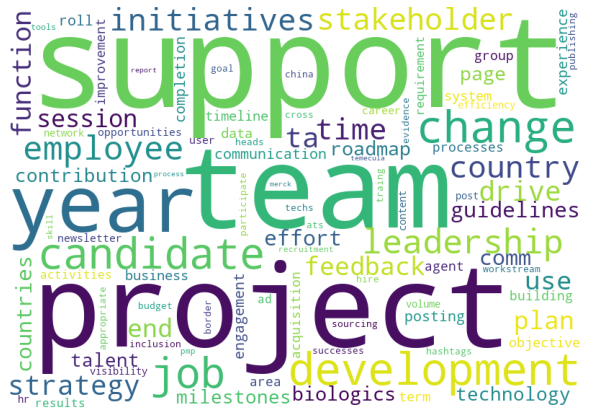

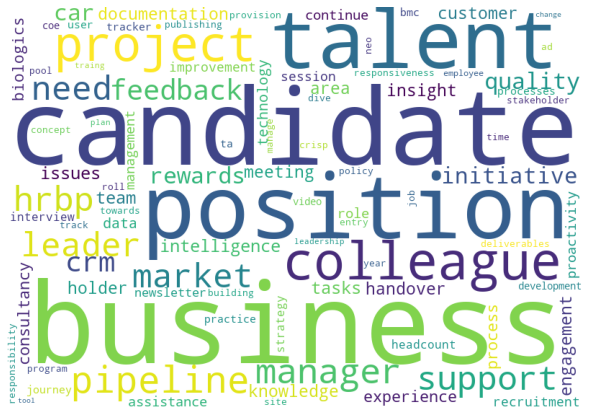

In [11]:
# visualize and save img
#visualize(TopicModelObject)
for i in range(TopicModelObject.k):
    get_wordcloud(TopicModelObject, token_lists, i)

Getting vector representations for LDA 
Dictionary used for LDA 

0 initiatives
1 leadership
2 projects
3 strategy
4 support
5 year
6 areas
7 coe
8 continue
9 rapport
10 relationship
11 strengthen
12 employee
13 drive
14 efforts
15 inclusion
16 kathy
17 business
18 leaders
19 partner
20 partnership
21 analysis
22 learnings
23 learns
24 lunch
25 n
26 optimization
27 skills
28 traings
29 contributions
30 thank
31 caprice
32 november
33 fact
34 ideas
35 judgements
36 thoughts
37 value
38 buy
39 decision
40 making
41 obtaing
42 team
43 abilities
44 compensation
45 relationships
46 s
47 strides
48 forum
49 opportunities
50 women
51 changes
52 growth
53 level
54 org
55 organization
56 path
57 planning
58 production
59 re
60 role
61 structure
62 bias
63 development
64 employees
65 feedback
66 learning
67 plans
68 biologics
69 list
70 refresh
71 succession
72 talent
73 diversity
74 kpis
75 visibility
76 area
77 initiative
78 site
79 appropriate
80 programs
81 managers
82 sessions
83 animal
84 

[(81, 1), (376, 1), (405, 1), (586, 1)]
[(60, 1), (72, 1), (590, 1), (591, 1), (592, 1)]
[(3, 1), (17, 2), (65, 2), (81, 1), (150, 1), (162, 2), (171, 1), (234, 1), (285, 1), (332, 1), (338, 2), (339, 1), (354, 1), (355, 1), (356, 1), (357, 1), (358, 1), (359, 1), (360, 1), (361, 1), (593, 1), (594, 1)]
[(208, 1), (227, 2), (234, 2), (329, 1), (609, 1), (610, 1), (611, 1), (612, 1), (613, 1)]
[(7, 1), (608, 1), (614, 1), (615, 1)]
[(321, 1), (608, 1), (616, 1), (617, 1), (618, 1)]
[(49, 1), (319, 1), (327, 1), (358, 1)]
[(27, 1), (63, 1), (587, 1)]
[(4, 1), (17, 1), (72, 1), (198, 1), (299, 1), (300, 1), (333, 1), (546, 1), (569, 1), (619, 1), (620, 1), (621, 1), (622, 1), (623, 1), (624, 1), (625, 1)]
[(0, 1), (2, 1), (4, 1), (13, 1), (14, 1), (233, 1), (244, 1), (245, 1), (324, 1), (326, 1), (327, 1), (344, 1), (626, 1), (627, 1)]
[(72, 1), (289, 2), (300, 1), (349, 1), (488, 1), (585, 1), (625, 1), (628, 1), (629, 1), (630, 1)]
[(208, 1), (227, 2), (234, 2), (329, 1), (609, 1), (610


 
 Shape of LDA Vector:  (852, 3)
[[0.0566229  0.88680911 0.05656796]
 [0.07028151 0.86142677 0.06829167]
 [0.04636745 0.91189927 0.04173329]
 ...
 [0.04770211 0.51472616 0.4375717 ]
 [0.08722052 0.12057068 0.79220879]
 [0.04195672 0.04179168 0.9162516 ]]

 According to LDA, the top words for each topic should be, 
{0: [('project', 0.021485645), ('change', 0.020550156), ('end', 0.018667072), ('rewards', 0.016515523), ('car', 0.016512971), ('position', 0.015413987)], 1: [('support', 0.037144933), ('team', 0.025866503), ('projects', 0.025105536), ('initiatives', 0.02135504), ('candidate', 0.02082703), ('leadership', 0.01863779)], 2: [('business', 0.03939286), ('job', 0.023449466), ('feedback', 0.019650286), ('talent', 0.01956616), ('candidates', 0.018723847), ('quality', 0.016567137)]}
Getting vector representations for LDA. Done! 


 Getting vector representations for BERT 
Our final sentence embedding vector of shape: torch.Size([852, 1024])

 Concatenating both LDA(topic distribution

tasks have been handed over to yelin other colleague and back without any major issues
tasks have been handed over to yelin other colleague and back without any major issues
tasks have been handed over to yelin other colleague and back without any major issues
ownership for projects in area of responsibility taken and driven proactively
tasks have been handed over to yelin other colleague and back without any major issues
ownership for projects in area of responsibility taken and driven proactively
tasks have been handed over to yelin other colleague and back without any major issues
ownership for projects in area of responsibility taken and driven proactively
tasks have been handed over to yelin other colleague and back without any major issues
ownership for projects in area of responsibility taken and driven proactively
tasks have been handed over to yelin other colleague and back without any major issues
ownership for projects in area of responsibility taken and driven proactively
t

Getting wordcloud for topic 0. Done!
Getting wordcloud for topic 1 ...
Getting wordcloud for topic 1. Done!
Getting wordcloud for topic 2 ...
Getting wordcloud for topic 2. Done!


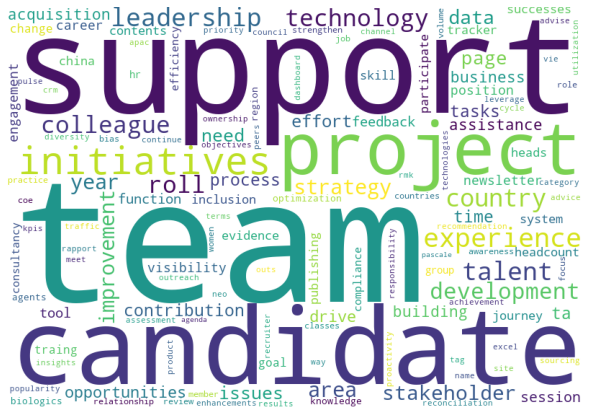

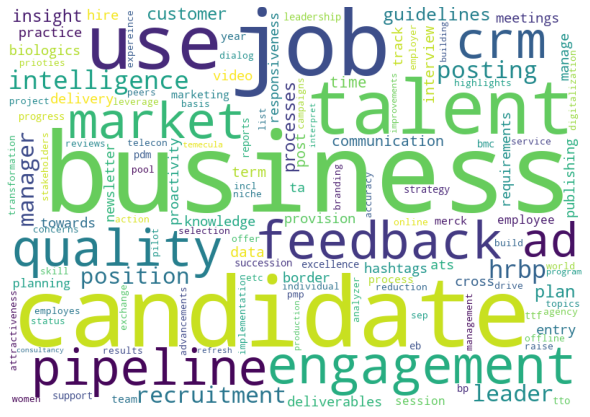

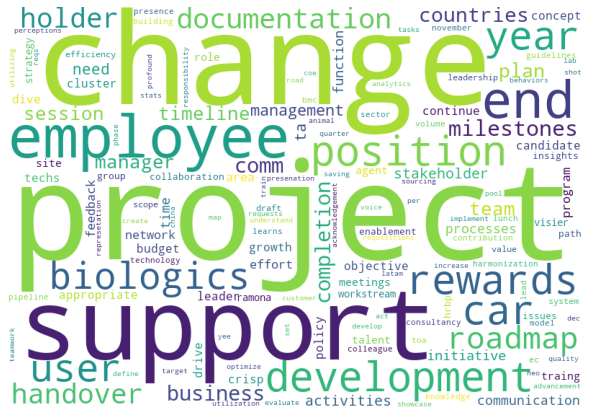

In [12]:
# Define the topic model object
TopicModelObject = Topic_Model(k = 3, verbose = Verbose)

# Fit the topic model
TopicModelObject.fit(sentences, token_lists)

labels = set(TopicModelObject.cluster_model.labels_)
for label in labels:
    index = []
    for idx, l in enumerate(TopicModelObject.cluster_model.labels_):
        if l == label:
            index.append(idx)
    print ('\n \nSentences belong to cluster ', str (label+1), ' are: \n ')
    for i in index:
        print (sentences[i])

## Visualizations

from utilities.visualizations import *
%matplotlib inline

for i in range(TopicModelObject.k):
    get_wordcloud(TopicModelObject, token_lists, i)



Getting vector representations for LDA 
Dictionary used for LDA 

0 initiatives
1 leadership
2 projects
3 strategy
4 support
5 year
6 areas
7 coe
8 continue
9 rapport
10 relationship
11 strengthen
12 employee
13 drive
14 efforts
15 inclusion
16 kathy
17 business
18 leaders
19 partner
20 partnership
21 analysis
22 learnings
23 learns
24 lunch
25 n
26 optimization
27 skills
28 traings
29 contributions
30 thank
31 caprice
32 november
33 fact
34 ideas
35 judgements
36 thoughts
37 value
38 buy
39 decision
40 making
41 obtaing
42 team
43 abilities
44 compensation
45 relationships
46 s
47 strides
48 forum
49 opportunities
50 women
51 changes
52 growth
53 level
54 org
55 organization
56 path
57 planning
58 production
59 re
60 role
61 structure
62 bias
63 development
64 employees
65 feedback
66 learning
67 plans
68 biologics
69 list
70 refresh
71 succession
72 talent
73 diversity
74 kpis
75 visibility
76 area
77 initiative
78 site
79 appropriate
80 programs
81 managers
82 sessions
83 animal
84 


 
 Shape of LDA Vector:  (852, 5)
[[0.03363666 0.03369595 0.54628849 0.03396255 0.35241634]
 [0.04018098 0.0400009  0.04139741 0.04069878 0.83772194]
 [0.02506408 0.0250685  0.89970666 0.02509576 0.02506499]
 ...
 [0.02857218 0.88562542 0.02860583 0.02860321 0.0285933 ]
 [0.05026974 0.79849547 0.05000143 0.05095804 0.05027536]
 [0.89891237 0.02599642 0.02500121 0.02502911 0.02506091]]

 According to LDA, the top words for each topic should be, 
{0: [('business', 0.050975263), ('talent', 0.02708535), ('crm', 0.026170775), ('pipeline', 0.020994792), ('candidate', 0.02093623), ('positions', 0.019344417)], 1: [('candidates', 0.03459113), ('quality', 0.03399441), ('job', 0.03219186), ('feedback', 0.026885685), ('use', 0.022584645), ('processes', 0.022583881)], 2: [('support', 0.052463576), ('business', 0.038401395), ('initiatives', 0.026505912), ('biologics', 0.024518218), ('drive', 0.023548977), ('needs', 0.021588596)], 3: [('team', 0.02245212), ('year', 0.018948112), ('issues', 0.0187152

Getting wordcloud for topic 0. Done!
Getting wordcloud for topic 1 ...
Getting wordcloud for topic 1. Done!
Getting wordcloud for topic 2 ...
Getting wordcloud for topic 2. Done!
Getting wordcloud for topic 3 ...
Getting wordcloud for topic 3. Done!
Getting wordcloud for topic 4 ...
Getting wordcloud for topic 4. Done!


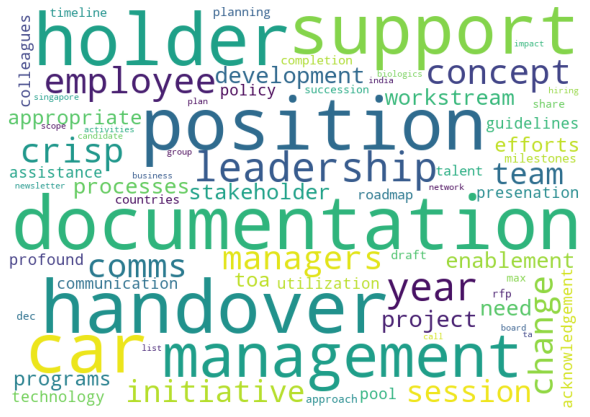

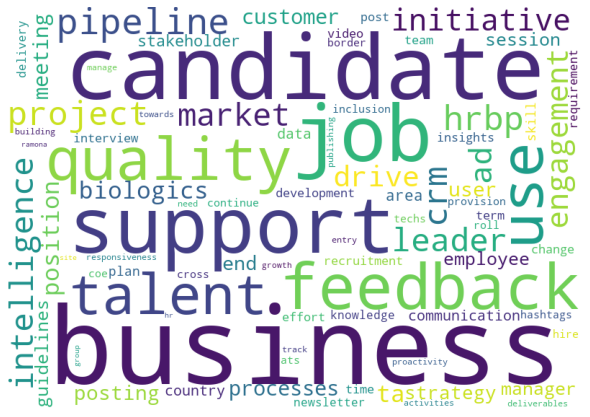

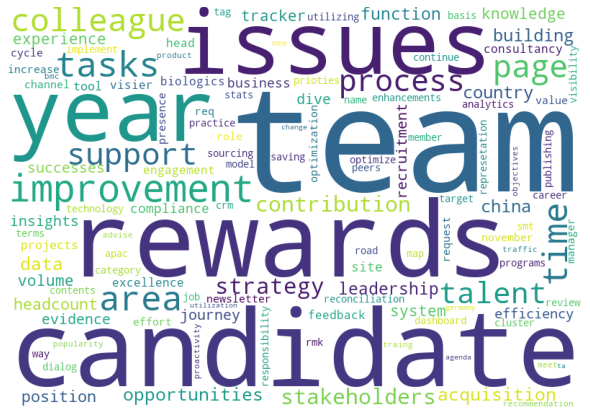

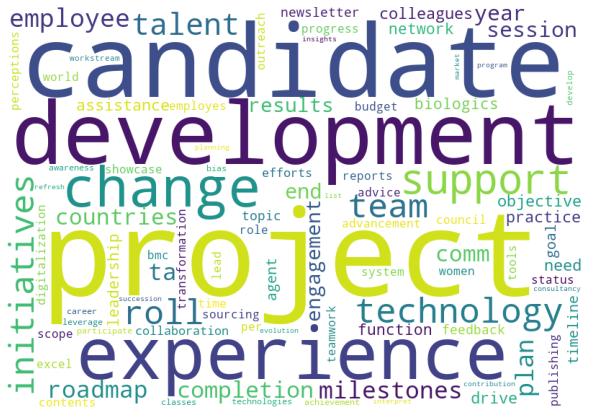

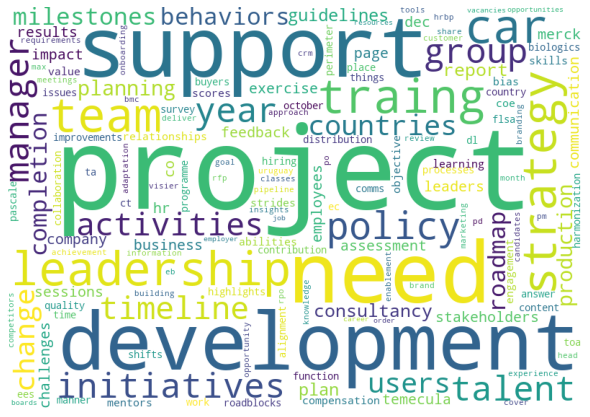

In [14]:
# Define the topic model object
TopicModelObject = Topic_Model(k = 5, verbose = Verbose)

# Fit the topic model
TopicModelObject.fit(sentences, token_lists)

labels = set(TopicModelObject.cluster_model.labels_)
for label in labels:
    index = []
    for idx, l in enumerate(TopicModelObject.cluster_model.labels_):
        if l == label:
            index.append(idx)
    print ('\n \nSentences belong to cluster ', str (label+1), ' are: \n ')
    for i in index:
        print (sentences[i])

## Visualizations

from utilities.visualizations import *
%matplotlib inline

for i in range(TopicModelObject.k):
    get_wordcloud(TopicModelObject, token_lists, i)
